# Intraday profile

How each weekday's requests spread over its 48 half-hours, and the daily forecast split into those half-hours.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.data import model_series, intraday_profile, spread_forecast

FIGURES = "../reports/figures/"
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

In [2]:
daily = pd.read_parquet("../data/daily.parquet")
interval = pd.read_parquet("../data/interval.parquet")
y, usable = model_series(daily)

clean = daily.index[(daily["gap_hours"] == 0) & usable.to_numpy()]
len(clean)

1058

## Has the shape changed?

In [3]:
older = intraday_profile(interval, clean[clean < "2025-10-31"])
recent = intraday_profile(interval, clean[clean >= "2025-10-31"])
(older - recent).abs().mean().mean() * 100

np.float64(0.11369697315306139)

The two years differ by about 0.1 percentage points per half-hour on average, so the shape is stable even though the channel mix moved. The profile below uses the last 52 weeks (358 days without any feed gap).

## Profile

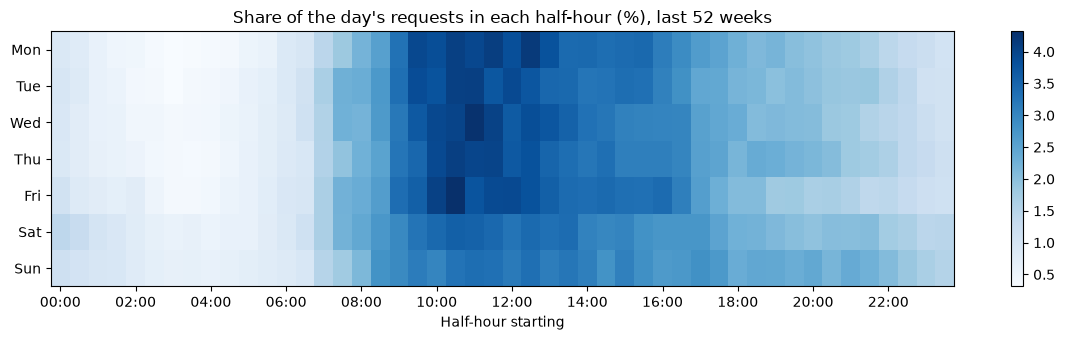

In [4]:
profile = recent

fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(profile * 100, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), DAYS)
ax.set_xticks(range(0, 48, 4), [str(t)[:5] for t in profile.columns[::4]])
ax.set_xlabel("Half-hour starting")
ax.set_title("Share of the day's requests in each half-hour (%), last 52 weeks")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES + "intraday_profile.png", dpi=150)
plt.show()

In [5]:
hourly = profile.T.groupby([t.hour for t in profile.columns]).sum().T * 100
hourly.index = DAYS
hourly.round(1)

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Mon,1.7,1.1,0.8,0.7,0.8,1.1,1.8,3.3,4.8,7.2,...,6.8,6.8,6.0,5.1,4.4,4.2,3.8,3.5,2.7,2.3
Tue,1.8,1.2,0.8,0.7,0.9,1.3,1.9,3.9,5.0,7.2,...,6.5,6.7,5.9,4.9,4.3,4.1,3.9,3.7,3.0,2.2
Wed,1.7,1.2,0.9,0.8,1.0,1.3,1.9,3.8,4.9,6.9,...,6.5,6.1,6.0,5.0,4.4,4.2,3.9,3.4,2.9,2.3
Thu,1.6,1.2,1.0,0.8,0.9,1.3,1.8,3.5,4.8,6.7,...,6.6,6.2,6.1,5.0,4.5,4.5,4.2,3.6,3.0,2.4
Fri,1.9,1.4,1.3,0.8,1.0,1.3,1.9,3.9,5.0,6.9,...,6.8,6.7,6.5,4.9,4.2,3.6,3.3,3.0,2.7,2.3
Sat,2.7,1.9,1.4,1.2,1.2,1.4,2.0,3.9,5.1,6.2,...,6.0,5.8,5.5,5.2,4.5,4.1,4.0,4.1,3.4,2.9
Sun,2.2,1.9,1.5,1.3,1.2,1.5,1.8,3.3,4.9,6.1,...,5.9,5.9,5.4,5.5,4.8,4.7,4.6,4.6,3.9,3.2


On weekdays requests climb from 7am, run at about 7 to 8% of the day per hour from 9am to 1pm and fade through the afternoon and evening. Weekends are flatter, with a lower midday peak and more of the day after 8pm. The busiest half-hours are around midday, at just over 4% of the day each, and the quietest is around 3am at about 0.3%.

## Forecast per half-hour

In [6]:
daily_forecast = pd.read_csv("../data/forecast_daily.csv", index_col="date", parse_dates=True)
by_interval = spread_forecast(daily_forecast["forecast"], profile)
len(by_interval), by_interval.sum(), daily_forecast["forecast"].sum()

(672, np.float64(33544.03127832999), np.float64(33544.03127832998))

In [7]:
by_interval.nlargest(5).round()

interval
2026-11-11 11:00:00    122.0
2026-11-04 11:00:00    121.0
2026-11-09 12:30:00    118.0
2026-11-09 11:30:00    116.0
2026-11-09 10:30:00    116.0
dtype: float64

In [8]:
by_interval.rename("forecast").to_csv("../data/forecast_interval.csv")

672 half-hours over the 14 days, adding back up to the daily total. The busiest is 11:00 on Wednesday 11 Nov at about 122 requests.